***file này để tiền xử lý dữ liệu cho bước tiếp theo***

In [1225]:
import cv2
import matplotlib.pyplot as plt
import sys
from pathlib import Path

# Tìm thư mục gốc bằng cách duyệt ngược cho đến khi thấy README.md
ROOT_DIR = Path.cwd().parent

sys.path.insert(0, str(ROOT_DIR))

from src.path import RAW_DATA_DIR, PROCESSED_DATA_DIR

***load data***

Đường dẫn: c:\Users\thien\Downloads\CPV_Project\CPV301\data\raw\TUSimple\road_sample_10.jpg
Kích thước: 1280 x 720 pixels


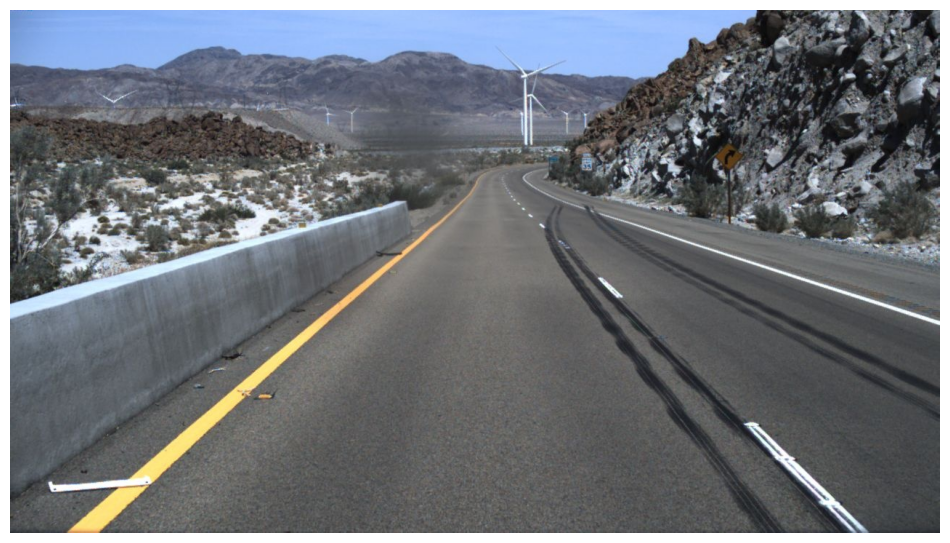

In [1226]:
# Lấy danh sách file ảnh trong RAW_DATA_DIR
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

image_files = [
    p for p in Path(RAW_DATA_DIR).rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
]

if not image_files:
    print(f"Không tìm thấy ảnh trong: {RAW_DATA_DIR}")
else:
    image_path = image_files[9]                        
    image = cv2.imread(str(image_path))

    if image is None:
        print(f"Không thể đọc ảnh: {image_path}")
    else:
        image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        print(f"Đường dẫn: {image_path}")
        print(f"Kích thước: {image.shape[1]} x {image.shape[0]} pixels")

        plt.figure(figsize=(12, 7))
        plt.imshow(image_rgb)
        plt.axis("off")
        plt.show()

***bắt đầu xử lý***

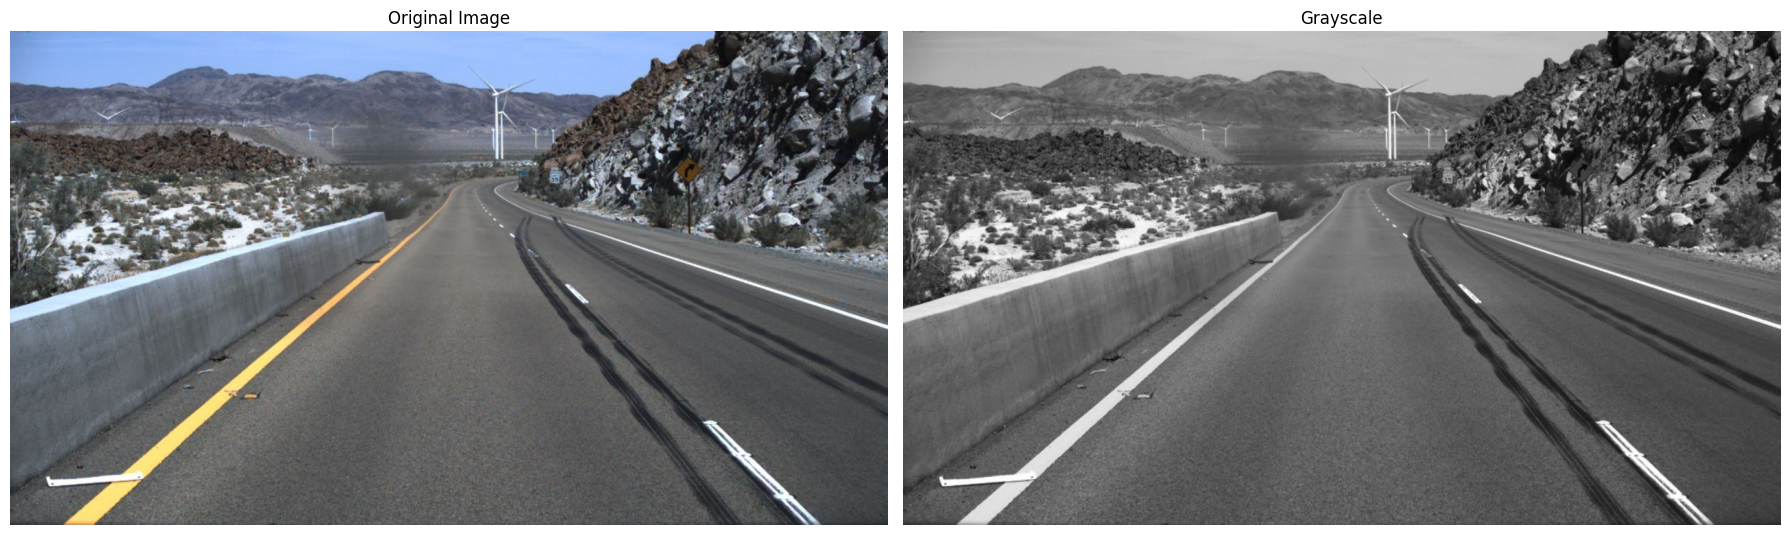

In [1227]:
# 1. Chuyển ảnh sang thang độ xám
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)


# 3. So sánh kết quả
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

axes[0].imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
axes[0].set_title("Original Image")

axes[1].imshow(gray, cmap="gray")
axes[1].set_title("Grayscale")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


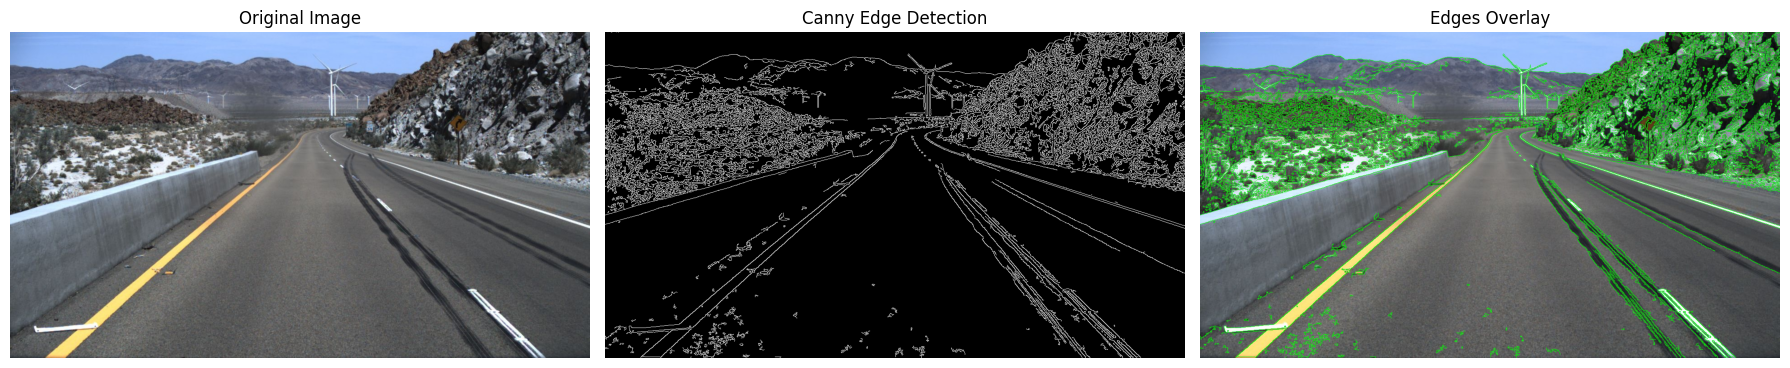

In [1228]:
# 1. Phát hiện biên trên ảnh xám
edges = cv2.Canny(gray, threshold1=50, threshold2=150)

# 2. Vẽ các đường biên lên ảnh gốc
edge_overlay = image.copy()
edge_overlay[edges > 0] = [0, 255, 0]  # Biên màu xanh lá (BGR)

# 3. Hiển thị kết quả
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
axes[0].set_title("Original Image")

axes[1].imshow(edges, cmap="gray")
axes[1].set_title("Canny Edge Detection")

axes[2].imshow(cv2.cvtColor(edge_overlay, cv2.COLOR_BGR2RGB))
axes[2].set_title("Edges Overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


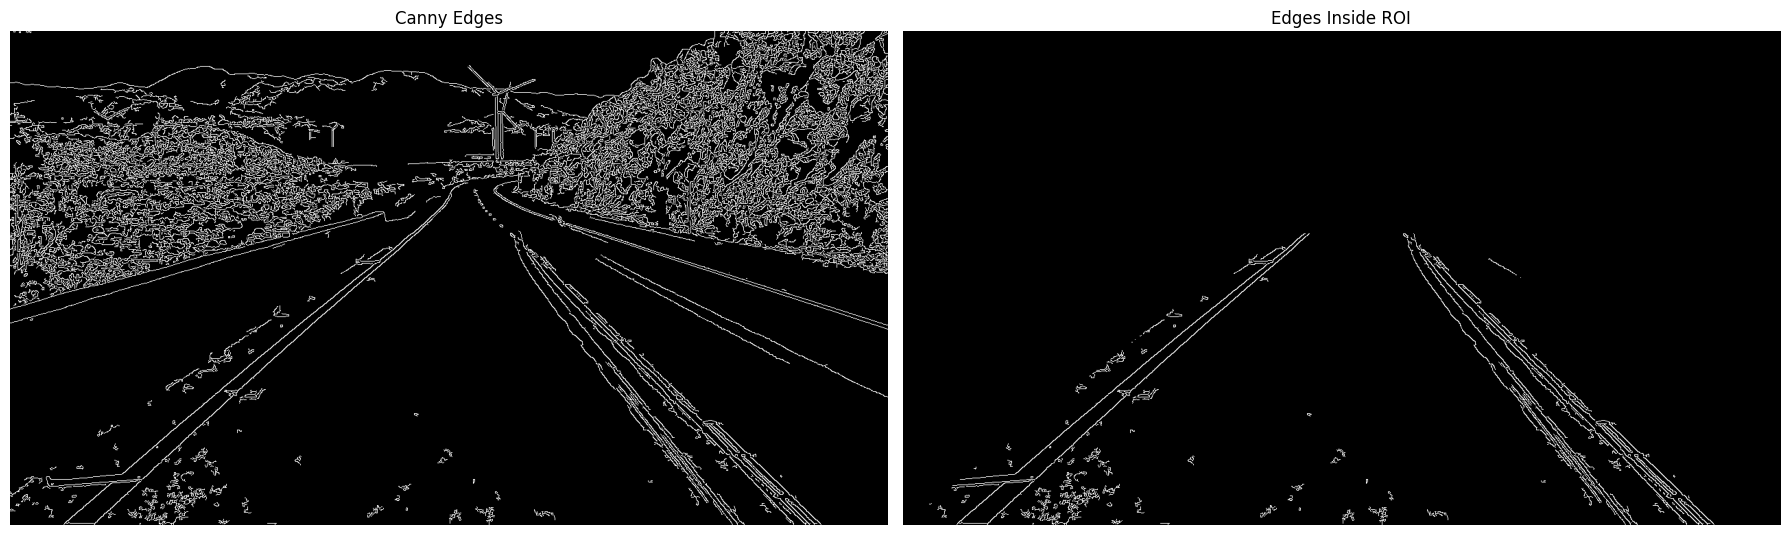

In [1229]:
import numpy as np
# Kích thước ảnh
height, width = edges.shape[:2]

# Khung ROI theo hình bạn đánh dấu
roi_vertices = np.array([[
    (0, height),                                # P1: Đáy trái
    (int(width * 0.415), int(height * 0.41)),   # P2: đỉnh trái (~531, 295)
    (int(width * 0.63), int(height * 0.41)),    # P3: đỉnh phải (~806, 295)
    (width - 1, int(height * 0.86)),            # P4: chạm mép phải (~1279, 620)
    (width - 1, height - 1)                     # P5: Đáy phải
]], dtype=np.int32)
#chỉnh cho nó cao cao cho nó nhìn xa hơn để thấy đc góc cua phía xa

# Tạo mask: vùng bên trong khung là trắng, bên ngoài là đen
mask = np.zeros_like(edges)
cv2.fillPoly(mask, roi_vertices, 255)

# Chỉ giữ các cạnh nằm trong ROI
roi_edges = cv2.bitwise_and(edges, mask)

# Hiển thị kết quả
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

axes[0].imshow(edges, cmap="gray")
axes[0].set_title("Canny Edges")

axes[1].imshow(roi_edges, cmap="gray")
axes[1].set_title("Edges Inside ROI")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

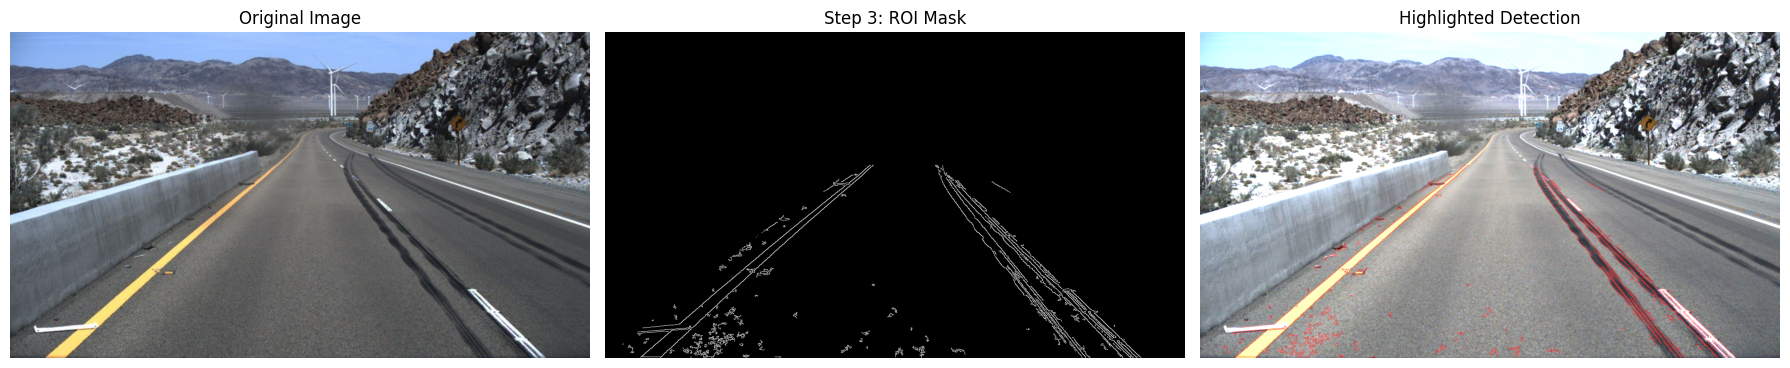

In [1230]:
# Ảnh gốc và mask phải có cùng kích thước
# roi_edges là kết quả bước 3 của bạn
assert image.shape[:2] == roi_edges.shape[:2], \
    "Kích thước ảnh gốc và ROI mask không khớp"

# Chỉ lấy vị trí các pixel đã được giữ lại ở bước 3
detected_mask = roi_edges > 0

# Tạo ảnh làm nổi bật các vị trí phát hiện
highlighted = image.copy()

# Tô đỏ lên vị trí phát hiện để dễ kiểm tra
highlighted[detected_mask] = (0, 0, 255)  # BGR

# Trộn nhẹ với ảnh gốc để vẫn nhìn thấy cảnh vật
result = cv2.addWeighted(image, 0.65, highlighted, 0.9, 0)

# Hiển thị ảnh gốc, mask và ảnh đối chiếu
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
axes[0].set_title("Original Image")

axes[1].imshow(roi_edges, cmap="gray")
axes[1].set_title("Step 3: ROI Mask")

axes[2].imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
axes[2].set_title("Highlighted Detection")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

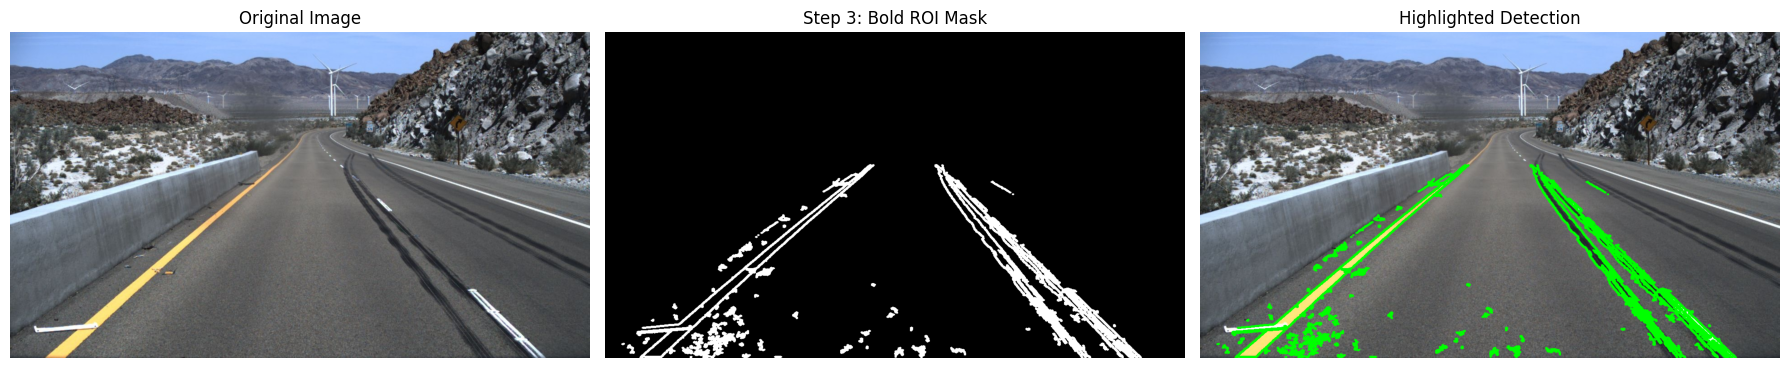

In [1231]:
# Ảnh gốc và mask phải có cùng kích thước
# roi_edges là kết quả bước 3 của bạn
assert image.shape[:2] == roi_edges.shape[:2], \
    "Kích thước ảnh gốc và ROI mask không khớp"

# 1. Làm dày (tô đậm) đường viền từ roi_edges bằng phép giãn nở (Dilate)
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
bold_roi_edges = cv2.dilate(roi_edges, kernel, iterations=1)

# 2. Chỉ lấy vị trí các pixel đã được làm đậm
detected_mask = bold_roi_edges > 0

# 3. Tô đậm màu xanh lá trực tiếp lên vị trí phát hiện
result = image.copy()
result[detected_mask] = (0, 255, 0)  # BGR: Xanh lá đậm sắc nét

# 4. Hiển thị ảnh gốc, mask đã làm đậm và ảnh đối chiếu
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
axes[0].set_title("Original Image")

axes[1].imshow(bold_roi_edges, cmap="gray")
axes[1].set_title("Step 3: Bold ROI Mask")

axes[2].imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
axes[2].set_title("Highlighted Detection")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

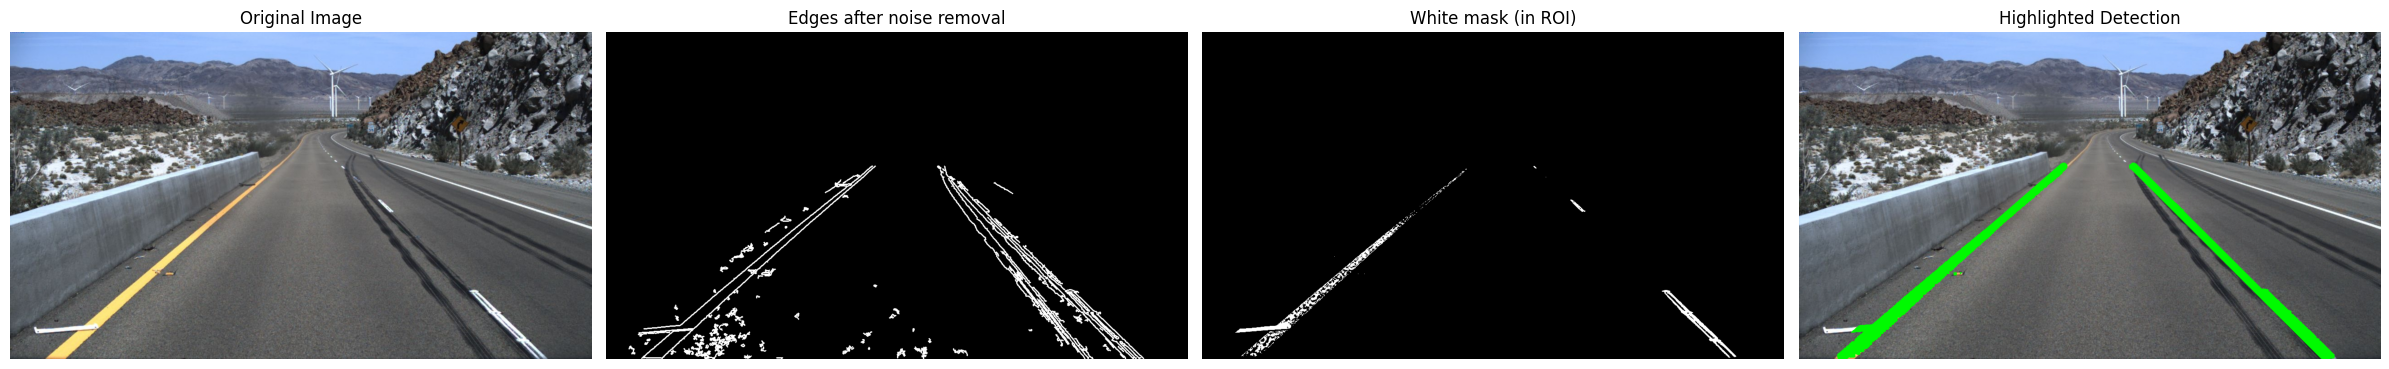

In [1232]:
# Cần có sẵn từ các cell trước: image, roi_edges, roi_vertices, mask (mask ROI)
height, width = image.shape[:2]
y_bottom = height - 1
y_top = int(roi_vertices[:, :, 1].min())   # đỉnh ROI (y nhỏ nhất)


# ---------- Bước 4: Lọc nhiễu trên ảnh viền ----------
def remove_small_blobs(edges, min_area=30):
    """Xóa các đốm viền nhỏ (vân nhựa đường, vết bẩn) trước khi chạy Hough."""
    n, labels, stats, _ = cv2.connectedComponentsWithStats(edges, connectivity=8)
    cleaned = np.zeros_like(edges)
    for i in range(1, n):  # bỏ nhãn 0 (nền)
        if stats[i, cv2.CC_STAT_AREA] >= min_area:
            cleaned[labels == i] = 255
    return cleaned


clean_edges = remove_small_blobs(roi_edges, min_area=10)
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
clean_edges = cv2.dilate(clean_edges, kernel, iterations=1)

# ---------- Bước 5: Hough Transform ----------
lines = cv2.HoughLinesP(
    clean_edges,
    rho=1,
    theta=np.pi / 180,
    threshold=12,
    minLineLength=15,
    maxLineGap=150,
)

# ---------- Bước 6: Lọc theo độ dốc, chia trái / phải, gán trọng số ----------
MIN_ABS_SLOPE = 0.5
left_pts, left_w = [], []    # điểm (x, y) và trọng số = độ dài đoạn
right_pts, right_w = [], []

if lines is not None:
    for x1, y1, x2, y2 in lines.reshape(-1, 4):
        if x2 == x1:
            continue
        slope = (y2 - y1) / (x2 - x1)
        if abs(slope) < MIN_ABS_SLOPE:  # bỏ đoạn gần nằm ngang
            continue
        length = np.hypot(x2 - x1, y2 - y1)
        # slope âm = vạch trái, slope dương = vạch phải (trục y hướng xuống)
        if slope < 0 and max(x1, x2) < width * 0.6:
            left_pts += [(x1, y1), (x2, y2)]
            left_w += [length, length]
        elif slope > 0 and min(x1, x2) > width * 0.4:
            right_pts += [(x1, y1), (x2, y2)]
            right_w += [length, length]


# ---------- Bước 7: Gộp thành một đường thẳng mỗi bên ----------
def fit_line(points, weights):
    """Fit x = a*y + b có trọng số (đoạn dài ưu tiên hơn đoạn ngắn)."""
    if len(points) < 2:
        return None
    pts = np.array(points)
    a, b = np.polyfit(pts[:, 1], pts[:, 0], deg=1, w=np.array(weights))
    return (int(a * y_bottom + b), y_bottom, int(a * y_top + b), y_top)


left_line = fit_line(left_pts, left_w)
right_line = fit_line(right_pts, right_w)

# ---------- Bước 8: Tinh chỉnh đường theo vùng trắng của vạch ----------
WHITE_L_MIN = 190   # ngưỡng độ sáng
BAND = 30           # nửa bề rộng dải tìm kiếm quanh đường ban đầu (px)

hls = cv2.cvtColor(image, cv2.COLOR_BGR2HLS)
white_mask = cv2.inRange(hls, (0, WHITE_L_MIN, 0), (255, 255, 255))
white_mask = cv2.bitwise_and(white_mask, mask)
ys, xs = np.nonzero(white_mask)


def refine_with_white(line):
    """Fit lại đường trên các pixel trắng nằm trong dải ±BAND quanh đường ban đầu."""
    if line is None:
        return None
    x_b, y_b, x_t, y_t = line
    a = (x_t - x_b) / (y_t - y_b)
    x_line = x_b + a * (ys - y_b)
    keep = (np.abs(xs - x_line) < BAND) & (ys >= y_t)
    if keep.sum() < 50:      # quá ít điểm trắng thì giữ đường cũ
        return line
    a2, b2 = np.polyfit(ys[keep], xs[keep], deg=1)
    return (int(a2 * y_bottom + b2), y_bottom, int(a2 * y_top + b2), y_top)


left_line = refine_with_white(left_line)
right_line = refine_with_white(right_line)

# ---------- Vẽ đường xanh lên ảnh gốc ----------
GREEN = (0, 250, 0)   # BGR
white_fat = cv2.dilate(white_mask, np.ones((7, 7), np.uint8))

result = image.copy()
for ln in (left_line, right_line):
    if ln is None:
        continue
    p1, p2 = (ln[0], ln[1]), (ln[2], ln[3])

    # 1) Phủ xanh các pixel trắng nằm trong dải quanh đường
    band_layer = np.zeros(image.shape[:2], np.uint8)
    cv2.line(band_layer, p1, p2, 255, thickness=2 * BAND)
    result[cv2.bitwise_and(white_fat, band_layer) > 0] = GREEN

    # 2) Vẽ nét đường chính đè lên để đường luôn liền mạch
    cv2.line(result, p1, p2, GREEN, thickness=15, lineType=cv2.LINE_AA)

# ---------- Hiển thị ----------
panels = [(cv2.cvtColor(image, cv2.COLOR_BGR2RGB), "Original Image"),
          (clean_edges, "Edges after noise removal"),
          (white_mask, "White mask (in ROI)"),
          (cv2.cvtColor(result, cv2.COLOR_BGR2RGB), "Highlighted Detection")]

fig, axes = plt.subplots(1, 4, figsize=(24, 6))
for ax, (img, title) in zip(axes, panels):
    ax.imshow(img, cmap="gray" if img.ndim == 2 else None)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [1233]:
# Xuất ảnh Highlighted Detection vào thư mục processed
from pathlib import Path

try:
  from src.path import PROCESSED_DATA_DIR
except ImportError:
  PROCESSED_DATA_DIR = Path.cwd().parent / "data" / "processed"

PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)

# Đặt tên file xuất (theo tên ảnh gốc nếu có, hoặc tên mặc định)
if "image_path" in globals() and hasattr(image_path, "name"):
  output_filename = f"highlighted_{image_path.name}"
else:
  output_filename = "highlighted_detection.jpg"

output_path = PROCESSED_DATA_DIR / output_filename

# Lưu ảnh (biến `result` là ảnh BGR có vẽ làn xanh)
success = cv2.imwrite(str(output_path), result)

if success:
  print(f"Đã xuất ảnh thành công vào thư mục processed:")
  print(f"-> {output_path}")
else:
  print(f"Lỗi: Không thể lưu ảnh vào {output_path}")

Đã xuất ảnh thành công vào thư mục processed:
-> c:\Users\thien\Downloads\CPV_Project\CPV301\data\processed\highlighted_road_sample_10.jpg
